In [202]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [203]:
df = pd.read_csv("titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [204]:
df.shape

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [205]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


In [206]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

X = df[features].copy()
y = df["Survived"].to_numpy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (891, 7)
Target shape: (891,)


In [207]:
np.random.seed(100)

indices = np.random.permutation(len(X))

test_size = int(0.2 * len(X))

test_indices = indices[:test_size]
train_indices = indices[test_size:]

X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

y_train = y[train_indices]
y_test = y[test_indices]

print("Training set:", X_train.shape, y_train.shape)
print("Testing set:", X_test.shape, y_test.shape)

Training set: (713, 7) (713,)
Testing set: (178, 7) (178,)


In [208]:
print(X_train.isnull().sum())

Pclass        0
Sex           0
Age         145
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


In [209]:
age_median = X_train["Age"].median()
embarked_mode = X_train["Embarked"].mode()[0]

X_train["Age"] = X_train["Age"].fillna(age_median)
X_test["Age"] = X_test["Age"].fillna(age_median)

X_train["Embarked"] = X_train["Embarked"].fillna(embarked_mode)
X_test["Embarked"] = X_test["Embarked"].fillna(embarked_mode)

print("Remaining missing values in training set:")
print(X_train.isnull().sum())

print("\nRemaining missing values in test set:")
print(X_test.isnull().sum())

Remaining missing values in training set:
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

Remaining missing values in test set:
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [210]:
embarked_modes = X_train["Embarked"].mode()

print("Mode:")
print(embarked_modes)

Mode:
0    S
Name: Embarked, dtype: str


In [211]:
embarked_mode = X_train["Embarked"].mode()[0]

In [212]:
X_train["Embarked"] = X_train["Embarked"].fillna(embarked_mode)
X_test["Embarked"] = X_test["Embarked"].fillna(embarked_mode)

In [213]:
X_train = pd.get_dummies(
    X_train,
    columns=["Sex", "Embarked"],
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=["Sex", "Embarked"],
    dtype=int
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print(X_train.head())
print("\nFeature columns:")
print(X_train.columns.tolist())

     Pclass   Age  SibSp  Parch      Fare  Sex_female  Sex_male  Embarked_C  \
852       3   9.0      1      1   15.2458           1         0           1   
408       3  21.0      0      0    7.7750           0         1           0   
480       3   9.0      5      2   46.9000           0         1           0   
510       3  29.0      0      0    7.7500           0         1           0   
609       1  40.0      0      0  153.4625           1         0           0   

     Embarked_Q  Embarked_S  
852           0           0  
408           0           1  
480           0           1  
510           1           0  
609           0           1  

Feature columns:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


Standardizing the numerical columns using:
z=(x-mu)/sigma

In [214]:
numeric_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

means = X_train[numeric_features].mean()
stds = X_train[numeric_features].std(ddof=0)

stds = stds.replace(0, 1)

X_train[numeric_features] = (X_train[numeric_features] - means) / stds

X_test[numeric_features] = (X_test[numeric_features] - means) / stds

In [215]:
X_train = X_train.to_numpy(dtype=float)
X_test = X_test.to_numpy(dtype=float)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (713, 10)
X_test: (178, 10)
y_train: (713,)
y_test: (178,)


In [216]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [217]:
test_values = np.array([-10, -2, 0, 2, 10])

print(sigmoid(test_values))

[4.53978687e-05 1.19202922e-01 5.00000000e-01 8.80797078e-01
 9.99954602e-01]


In [218]:
def compute_loss(y_true, y_pred):
    epsilon = 1e-15

    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

    return loss

In [219]:
y_example = np.array([1, 0, 1, 0])

predictions_good = np.array([0.9, 0.1, 0.8, 0.2])
predictions_bad = np.array([0.1, 0.9, 0.2, 0.8])

print("Good predictions:", compute_loss(y_example, predictions_good))
print("Bad predictions:", compute_loss(y_example, predictions_bad))

Good predictions: 0.164252033486018
Bad predictions: 1.9560115027140732


In [220]:
def train_logistic_regression(
    X, y, alpha, lam=0.0, iterations=1000
):
    m, n = X.shape

    w = np.zeros(n)
    b = 0.0
    losses = []

    for i in range(iterations):
       
        z = X @ w + b
        y_pred = sigmoid(z)
        
        errors = y_pred - y

        dw = (X.T @ errors) / m + (lam / m) * w
        db = np.mean(errors)

        w -= alpha * dw
        b -= alpha * db

        y_pred = sigmoid(X @ w + b)
        loss = compute_loss(y, y_pred)
        loss += (lam / (2 * m)) * np.sum(w ** 2)

        losses.append(loss)

    return w, b, losses

In [221]:
alphas = [0.001, 0.01, 0.1, 0.5]
iterations = 1000

results = {}

for alpha in alphas:
    w, b, losses = train_logistic_regression(
        X_train,
        y_train,
        alpha=alpha,
        iterations=iterations
    )

    results[alpha] = {
        "w": w,
        "b": b,
        "losses": losses
    }

    print(f"alpha={alpha}: final loss={losses[-1]:.4f}")

alpha=0.001: final loss=0.6066
alpha=0.01: final loss=0.4702
alpha=0.1: final loss=0.4381
alpha=0.5: final loss=0.4381


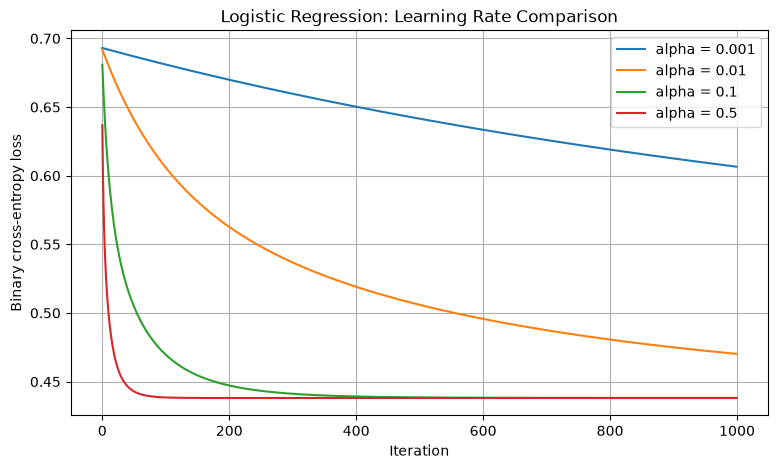

In [222]:
plt.figure(figsize=(9, 5))

for alpha, result in results.items():
    plt.plot(
        result["losses"],
        label=f"alpha = {alpha}"
    )

plt.xlabel("Iteration")
plt.ylabel("Binary cross-entropy loss")
plt.title("Logistic Regression: Learning Rate Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [223]:
lambdas = [0.0, 0.1, 1.0, 0.01, 10.0, 50.0, 100.0]

alpha = 0.1
iterations = 1000

regularization_results = {}

for lam in lambdas:
    w, b, losses = train_logistic_regression(
        X_train,
        y_train,
        alpha=alpha,
        lam=lam,
        iterations=iterations
    )

    regularization_results[lam] = {
        "w": w,
        "b": b,
        "losses": losses
    }

    print(
        f"lam={lam}: "
        f"final regularized loss={losses[-1]:.4f}"
    )

lam=0.0: final regularized loss=0.4381
lam=0.1: final regularized loss=0.4384
lam=1.0: final regularized loss=0.4416
lam=0.01: final regularized loss=0.4381
lam=10.0: final regularized loss=0.4667
lam=50.0: final regularized loss=0.5233
lam=100.0: final regularized loss=0.5559


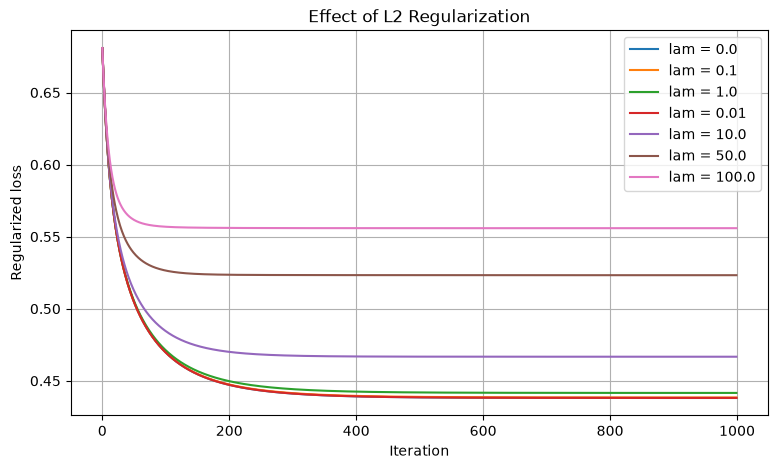

In [224]:
plt.figure(figsize=(9,5))

for lam, result in regularization_results.items():
    plt.plot(
        result["losses"],
        label=f"lam = {lam}"
    )

plt.xlabel("Iteration")
plt.ylabel("Regularized loss")
plt.title("Effect of L2 Regularization")
plt.legend()
plt.grid(True)
plt.show()

In [225]:
chosen_lam = 0.01

w = regularization_results[chosen_lam]["w"]
b = regularization_results[chosen_lam]["b"]

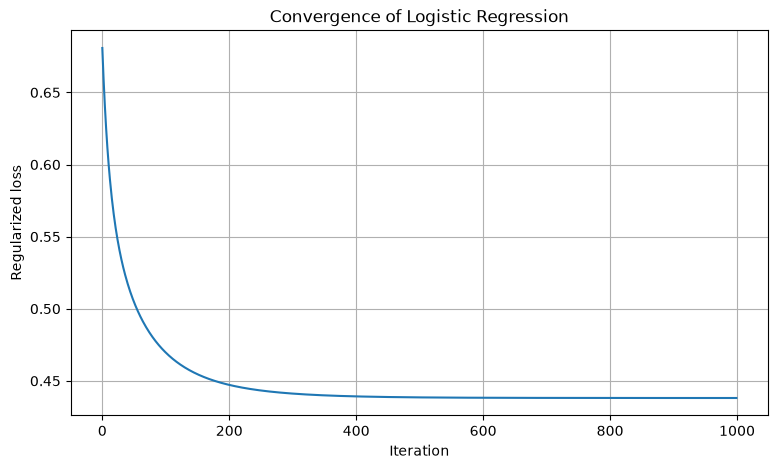

In [226]:
chosen_lam = 0.01
losses = regularization_results[chosen_lam]["losses"]

plt.figure(figsize=(9, 5))
plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("Regularized loss")
plt.title("Convergence of Logistic Regression")
plt.grid(True)
plt.show()

In [227]:
y_test_prob = sigmoid(X_test @ w + b)
y_test_pred = (y_test_prob >= 0.5).astype(int)

print("First 10 predicted probabilities:", y_test_prob[:10])
print("First 10 predicted classes:\t", y_test_pred[:10])
print("First 10 actual classes:\t", y_test[:10])

First 10 predicted probabilities: [0.79145528 0.74329216 0.0943578  0.66265216 0.16348456 0.69867216
 0.09009942 0.22042981 0.93599208 0.36562708]
First 10 predicted classes:	 [1 1 0 1 0 1 0 0 1 0]
First 10 actual classes:	 [0 1 1 1 0 0 0 0 1 0]


In [228]:
accuracy = np.mean(y_test_pred == y_test)

print(f"Test accuracy: {accuracy:.4f}")
print(f"Test accuracy: {accuracy * 100:.2f}%")

Test accuracy: 0.8090
Test accuracy: 80.90%


In [229]:
tn = np.sum((y_test == 0) & (y_test_pred == 0))
fp = np.sum((y_test == 0) & (y_test_pred == 1))
fn = np.sum((y_test == 1) & (y_test_pred == 0))
tp = np.sum((y_test == 1) & (y_test_pred == 1))

confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])

print(confusion_matrix)

[[91 12]
 [22 53]]


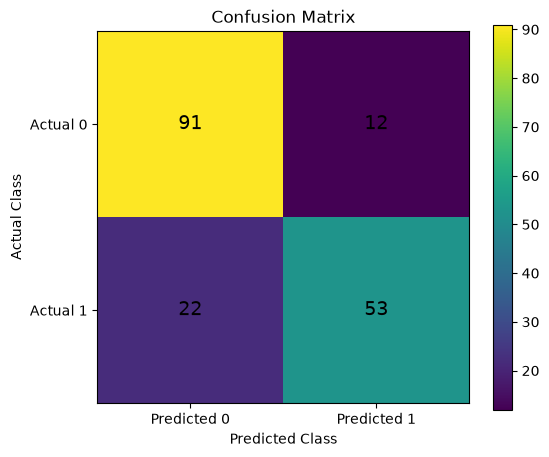

In [230]:
plt.figure(figsize=(6, 5))

plt.imshow(confusion_matrix)
plt.colorbar()

plt.xticks([0, 1], ["Predicted 0", "Predicted 1"])
plt.yticks([0, 1], ["Actual 0", "Actual 1"])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, confusion_matrix[i, j],
            ha="center", va="center", fontsize=14
        )

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")
plt.show()

In [231]:
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1_score = 2 * precision * recall / (precision + recall)

print(f"Precision: {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall:    {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1-score:  {f1_score:.4f}")

Precision: 0.8154 (81.54%)
Recall:    0.7067 (70.67%)
F1-score:  0.7571
